# 01 — Forward P0 model

One operating point flows through a graph: cards → (state step) → four mechanisms → detector.
A protocol turns an experiment into a list of operating points. All formulas are closed-form;
every result carries a status (`valid`, `approximate`, `unsupported`) and its reasons.
Demo cards and their sources are in `esm_p00/examples.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from langgraph.graph import END, START, StateGraph

from esm_p00 import detector, examples
from esm_p00.cards import ExperimentCard, JunctionCard, PulseCard
from esm_p00.mechanisms import electrostatic, electrostriction, piezoresponse, vegard
from esm_p00.protocols import FrequencySweep, PulseReadout
from esm_p00.state import PointState
from material_state import occupancy

lco = examples.licoo2()                 # Li0.5CoO2: mobile Li+, no d or Q
ferro = examples.polar_dielectric()     # illustrative PZT-like film: d, Q, P_0, no mobile ions
probe = examples.afm_probe()            # Si tip, k_l = 3 N/m, measured contact resonance f_cr and Q
junction = JunctionCard()               # CPD 0 and no surface layer: assumptions, not data
f_cr = probe.contact_resonance_hz.value

## 1. The graph

The state step runs only when the operating point has a pulse. The four mechanisms run in
parallel and never see each other; only the detector combines them.

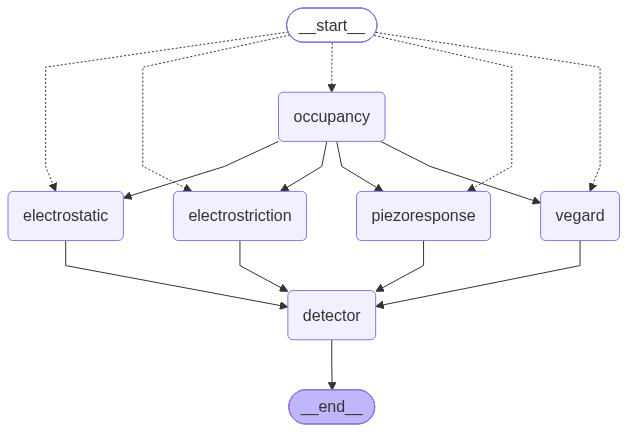

In [2]:
MECHANISMS = [vegard, piezoresponse, electrostriction, electrostatic]
names = [m.NAME for m in MECHANISMS]

builder = StateGraph(PointState)
builder.add_node("occupancy", occupancy.node)
for m in MECHANISMS:
    builder.add_node(m.NAME, m.node)
builder.add_node("detector", detector.node)
builder.add_conditional_edges(START, lambda s: "occupancy" if s.get("pulse") is not None else names,
                              ["occupancy", *names])
for name in names:
    builder.add_edge("occupancy", name)
builder.add_edge(names, "detector")                     # the detector waits for all four
builder.add_edge("detector", END)
graph = builder.compile()

try:
    display(Image(graph.get_graph().draw_mermaid_png()))                     # rendered online by mermaid.ink
except Exception:
    display(Markdown(f"```mermaid\n{graph.get_graph().draw_mermaid()}\n```"))   # offline: JupyterLab renders it

In [3]:
def run(material, experiment, pulse=None):
    """One operating point through the graph."""
    return graph.invoke({"material": material, "experiment": experiment, "instrument": probe,
                         "junction": junction, "pulse": pulse})


def signal(points, mechanism=None, harmonic="1w"):
    """Complex detector signal per point: the total, or one mechanism's share."""
    return np.array([p["detector"].total[harmonic] if mechanism is None
                     else p["detector"].per_mechanism[mechanism][harmonic] for p in points])


readout = ExperimentCard(vac_peak_v=0.002, vdc_v=0.01, frequency_hz=f_cr,
                         temperature_k=300.0, normal_load_n=50e-9)
point = run(lco, readout)
shares = {name: abs(z["1w"]) for name, z in point["detector"].per_mechanism.items()}
print(point["detector"].status, "| summed:", list(shares), "| omitted:", point["detector"].omitted)
print(f"at the contact resonance: electrostatic / Vegard = {shares['electrostatic'] / shares['vegard']:.1f}")

approximate | summed: ['electrostatic', 'vegard'] | omitted: ['electrostriction', 'piezoresponse']
at the contact resonance: electrostatic / Vegard = 3.2


`point["detector"].reasons` says why the result is approximate here: the Debye length is shorter
than the ion spacing, so continuum screening is formal, and there is a 10 mV DC offset.

## 2. Frequency sweep (LiCoO₂)

The drive is 2 mV, which stays in the small-signal window. A 10 mV DC offset makes the electrostatic
1ω force visible. Below the ionic crossover f_c, Vegard is the equilibrium screening response.
Above f_c it is transport-limited and falls as 1/f. Both channels are amplified by the contact
resonance.

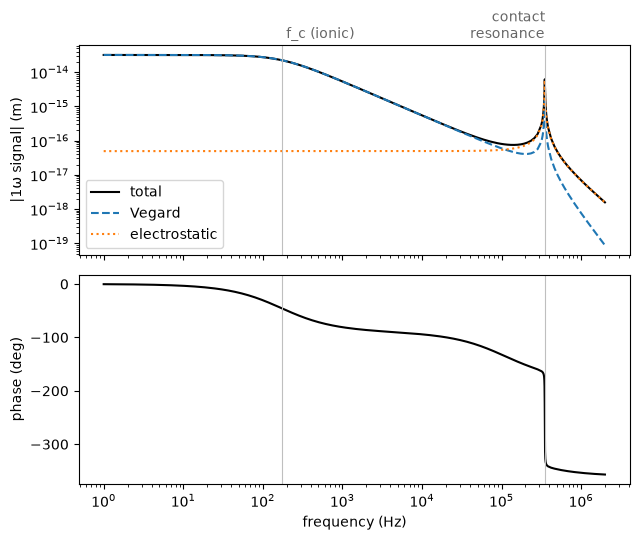

In [4]:
frequencies = np.unique(np.concatenate([np.logspace(0, 6.3, 150), np.linspace(0.9, 1.1, 81) * f_cr]))
steps = FrequencySweep(readout=readout, frequencies_hz=frequencies.tolist()).steps()
points = [run(lco, s.experiment) for s in steps]
f = np.array([s.x for s in steps])
f_c = next(r for r in points[0]["reports"] if r.mechanism == "vegard").scales_used["omega_c_rad_s"] / (2 * np.pi)

fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 5.5))
top.loglog(f, abs(signal(points)), "k", label="total")
top.loglog(f, abs(signal(points, "vegard")), "--", label="Vegard")
top.loglog(f, abs(signal(points, "electrostatic")), ":", label="electrostatic")
bottom.semilogx(f, np.degrees(np.unwrap(np.angle(signal(points)))), "k")
for ax in (top, bottom):
    ax.axvline(f_c, color="0.75", lw=0.8)
    ax.axvline(f_cr, color="0.75", lw=0.8)
top.text(f_c, 1e-13, " f_c (ionic)", color="0.4")
top.text(f_cr, 1e-13, " contact\n resonance", color="0.4", ha="right")
top.set_ylabel("|1ω signal| (m)")
bottom.set_ylabel("phase (deg)")
bottom.set_xlabel("frequency (Hz)")
top.legend(loc="lower left")
fig.tight_layout()

## 3. Pulse, then relaxation (LiCoO₂)

A 0.1 s DC pulse sets the occupancy θ under the tip. A positive tip empties Li sites. The readout
is off-field (0 V DC) at the contact resonance after a delay, with a 1 ms window. The state
recovers by diffusion over τ = a²/4D. The Vegard signal follows θ(1−θ), because only ions next to
an empty site can move.

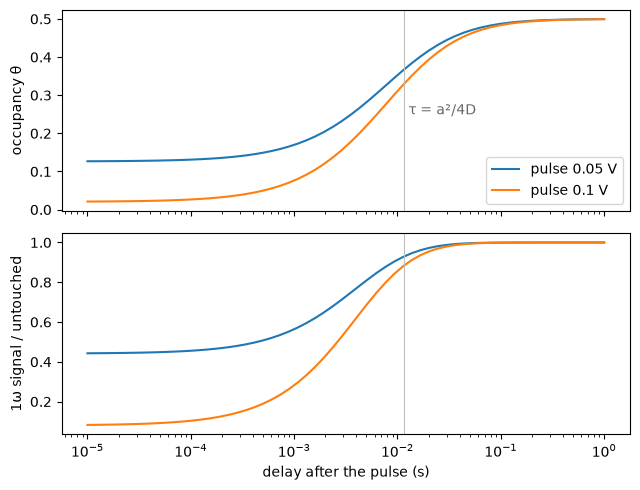

In [5]:
readout_off = ExperimentCard(vac_peak_v=0.002, vdc_v=0.0, frequency_hz=f_cr,
                             temperature_k=300.0, normal_load_n=50e-9)
delays = np.logspace(-5, 0, 60)
untouched = abs(signal([run(lco, readout_off)]))[0]

fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 5))
for pulse_v in (0.05, 0.1):
    protocol = PulseReadout(readout=readout_off, delays_s=delays.tolist(),
                            pulse=PulseCard(pulse_v=pulse_v, pulse_s=0.1, readout_s=1e-3))
    points = [run(lco, s.experiment, s.pulse) for s in protocol.steps()]
    top.semilogx(delays, [p["state_report"].values["theta"] for p in points], label=f"pulse {pulse_v} V")
    bottom.semilogx(delays, abs(signal(points)) / untouched)
tau = points[0]["state_report"].scales_used["tau_s"]
for ax in (top, bottom):
    ax.axvline(tau, color="0.75", lw=0.8)
top.text(tau, 0.25, " τ = a²/4D", color="0.4")
top.set_ylabel("occupancy θ")
bottom.set_ylabel("1ω signal / untouched")
bottom.set_xlabel("delay after the pulse (s)")
top.legend(loc="lower right")
fig.tight_layout()

## 4. Linear and quadratic channels (polar dielectric)

Same graph, another card. An AC amplitude sweep at 50 kHz gives two channels. Piezoresponse is
linear, so 1ω ∝ V. Electrostriction and the electrostatic force are quadratic, so 2ω ∝ V².
Vegard is omitted, because this card has no mobile ions. Filled markers are `valid`; open markers
are `approximate`, because the field under the tip exceeds the linear-dielectric limit.

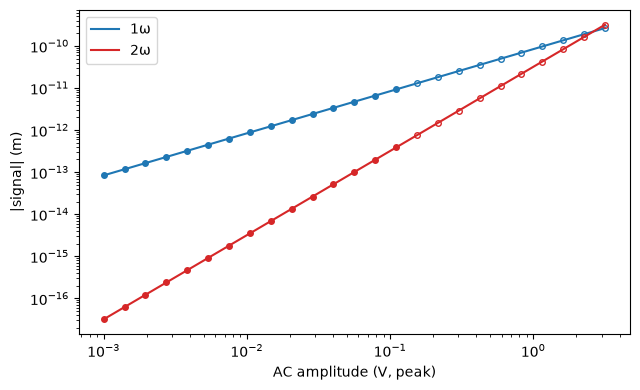

In [6]:
amplitudes = np.logspace(-3, 0.5, 25)
points = [run(ferro, ExperimentCard(vac_peak_v=v, frequency_hz=50e3, temperature_k=300.0, normal_load_n=50e-9))
          for v in amplitudes]
valid = np.array([p["detector"].status == "valid" for p in points])

fig, ax = plt.subplots(figsize=(6.5, 4))
for harmonic, color in (("1w", "C0"), ("2w", "C3")):
    y = abs(signal(points, harmonic=harmonic))
    ax.loglog(amplitudes, y, color=color, label=harmonic.replace("w", "ω"))
    ax.loglog(amplitudes[valid], y[valid], "o", color=color, ms=4)
    ax.loglog(amplitudes[~valid], y[~valid], "o", color=color, ms=4, mfc="none")
ax.set_xlabel("AC amplitude (V, peak)")
ax.set_ylabel("|signal| (m)")
ax.legend(loc="upper left")
fig.tight_layout()

## Reading the results

- Each point is one run of the same graph. Sweeps and pulse series are lists of points produced
  by a protocol.
- The detector is the only place where mechanisms meet. At the contact resonance, just 10 mV of
  DC offset makes the electrostatic term comparable to Vegard; section 1 prints the ratio.
- Statuses travel to the final signal: the detector is never better than the mechanisms and the
  state it was built on.